# Controlled Baseline EfficientNetB0 Training

This notebook trains the frozen EfficientNetB0 baseline for binary AMD versus Non-AMD classification. It uses the patient-level splits and preprocessing pipeline already validated in earlier project stages.

The test split is deliberately not loaded into a DataLoader or used for training decisions. Test evaluation belongs to a later, finalized-model phase.

## 1. Controlled training design

- EfficientNetB0 with ImageNet pretrained weights
- Frozen pretrained feature extractor and trainable binary classification head
- AdamW optimizer with learning rate `0.0001`
- `BCEWithLogitsLoss` with a training-derived positive-class weight
- 12 maximum epochs and early stopping patience of 4 epochs
- Best checkpoint selected primarily by validation ROC-AUC
- Fixed random seed of 42
- No hyperparameter tuning and no test evaluation

## 2. Imports, reproducibility, and paths

The active `.venv` contains PyTorch, TorchVision, scikit-learn, and Jupyter support.

In [1]:
from __future__ import annotations

import hashlib
import random
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, roc_auc_score
from torch import nn
from torch.utils.data import DataLoader, Dataset
from torchvision.models import EfficientNet_B0_Weights, efficientnet_b0

def find_project_root() -> Path:
    for candidate in [Path.cwd(), *Path.cwd().parents]:
        if (candidate / "data" / "raw" / "OCTDL").is_dir():
            return candidate
    raise FileNotFoundError("Could not find a project root containing data/raw/OCTDL.")

PROJECT_ROOT = find_project_root()
SRC_ROOT = PROJECT_ROOT / "src"
if str(SRC_ROOT) not in sys.path:
    sys.path.insert(0, str(SRC_ROOT))
from oct_preprocessing import preprocess_image

PROCESSED_ROOT = PROJECT_ROOT / "data" / "processed"
RESULTS_ROOT = PROJECT_ROOT / "results"
PLOTS_ROOT = RESULTS_ROOT / "plots"
MODEL_ROOT = PROJECT_ROOT / "models"
RESULTS_ROOT.mkdir(parents=True, exist_ok=True)
PLOTS_ROOT.mkdir(parents=True, exist_ok=True)
MODEL_ROOT.mkdir(parents=True, exist_ok=True)
CHECKPOINT_PATH = MODEL_ROOT / "baseline_efficientnetb0_best.pth"
HISTORY_PATH = RESULTS_ROOT / "baseline_training_history.csv"

RANDOM_SEED = 42
BATCH_SIZE = 16
NUM_WORKERS = 0
LEARNING_RATE = 1e-4
MAX_EPOCHS = 12
EARLY_STOPPING_PATIENCE = 4
RUN_TRAINING = True
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

def set_seed(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(RANDOM_SEED)
print(f"Selected device: {DEVICE}")
print(f"Maximum epochs: {MAX_EPOCHS}")
print(f"Checkpoint: {CHECKPOINT_PATH}")

Selected device: cpu
Maximum epochs: 12
Checkpoint: C:\Users\vibhu\OneDrive\图片\文档\AMD-Digital-Twin\models\baseline_efficientnetb0_best.pth


## 3. Safety checks before training

The split CSV hashes are recorded before training. Patient IDs are checked for disjointness. The test CSV is read only for this integrity check and is never passed to a model or optimizer.

In [2]:
split_paths = {name: PROCESSED_ROOT / f"{name}.csv" for name in ["train", "validation", "test"]}
split_hashes_before = {}
split_frames = {}
for split_name, split_path in split_paths.items():
    if not split_path.is_file():
        raise FileNotFoundError(f"Missing split file: {split_path}")
    split_hashes_before[split_name] = hashlib.sha256(split_path.read_bytes()).hexdigest()
    frame = pd.read_csv(split_path)
    frame["image_path_absolute"] = frame["image_path"].map(lambda value: PROJECT_ROOT / str(value))
    split_frames[split_name] = frame

patient_sets = {name: set(frame["patient_id"]) for name, frame in split_frames.items()}
overlaps = {
    "train_validation": len(patient_sets["train"] & patient_sets["validation"]),
    "train_test": len(patient_sets["train"] & patient_sets["test"]),
    "validation_test": len(patient_sets["validation"] & patient_sets["test"]),
}
if any(overlaps.values()):
    raise AssertionError(f"Patient overlap detected: {overlaps}")

train_frame = split_frames["train"]
validation_frame = split_frames["validation"]
if len(split_frames["test"]) != 307:
    print("Warning: test row count differs from the expected preparation report.")

print("Pre-training safety checks passed")
print(f"Train rows: {len(train_frame):,}; validation rows: {len(validation_frame):,}; test rows checked: {len(split_frames['test']):,}")
print(f"Patient overlaps: {overlaps}")
print("Test data will not be used in training or validation monitoring.")

Pre-training safety checks passed
Train rows: 1,428; validation rows: 327; test rows checked: 307
Patient overlaps: {'train_validation': 0, 'train_test': 0, 'validation_test': 0}
Test data will not be used in training or validation monitoring.


## 4. Dynamic datasets and loaders

Only train and validation loaders are constructed. Each image is loaded dynamically and passed through the validated preprocessing module.

In [3]:
class OCTDataset(Dataset):
    def __init__(self, frame: pd.DataFrame, augment: bool, seed: int = RANDOM_SEED):
        self.frame = frame.reset_index(drop=True).copy()
        self.augment = augment
        self.seed = seed

    def __len__(self) -> int:
        return len(self.frame)

    def __getitem__(self, index: int) -> tuple[torch.Tensor, torch.Tensor]:
        record = self.frame.iloc[index]
        rng = np.random.default_rng(self.seed + index) if self.augment else None
        array = preprocess_image(
            record["image_path_absolute"],
            augment=self.augment,
            rng=rng,
        )
        image = torch.from_numpy(array).float()
        label = torch.tensor(float(record["target_amd"]), dtype=torch.float32)
        return image, label

train_dataset = OCTDataset(train_frame, augment=True)
validation_dataset = OCTDataset(validation_frame, augment=False)
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS, pin_memory=torch.cuda.is_available())
validation_loader = DataLoader(validation_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=torch.cuda.is_available())

sample_images, sample_labels = next(iter(train_loader))
print(f"Train loader: {len(train_dataset):,} images")
print(f"Validation loader: {len(validation_dataset):,} images")
print(f"Sample image batch shape: {tuple(sample_images.shape)}")
print(f"Sample label batch shape: {tuple(sample_labels.shape)}")
assert sample_images.shape[1:] == (3, 224, 224)
assert sample_labels.shape == (sample_images.shape[0],)

Train loader: 1,428 images
Validation loader: 327 images
Sample image batch shape: (16, 3, 224, 224)
Sample label batch shape: (16,)


## 5. Class imbalance and loss

`pos_weight = non_AMD / AMD` is calculated from training labels only and passed to `BCEWithLogitsLoss`.

In [4]:
train_labels = train_frame["target_amd"].astype(int)
amd_count = int((train_labels == 1).sum())
non_amd_count = int((train_labels == 0).sum())
POS_WEIGHT = non_amd_count / amd_count
criterion = nn.BCEWithLogitsLoss(pos_weight=torch.tensor([POS_WEIGHT], device=DEVICE))
print(f"Training AMD images: {amd_count:,}")
print(f"Training non-AMD images: {non_amd_count:,}")
print(f"Calculated positive-class weight: {POS_WEIGHT:.6f}")
print(f"Training class distribution: {train_labels.value_counts(normalize=True).sort_index().to_dict()}")

Training AMD images: 858
Training non-AMD images: 570
Calculated positive-class weight: 0.664336
Training class distribution: {0: 0.39915966386554624, 1: 0.6008403361344538}


## 6. Build the frozen EfficientNetB0 model

The feature extractor remains frozen. Batch-normalization statistics in the frozen feature extractor are kept in evaluation mode during epochs to avoid changing pretrained representations.

In [5]:
weights = EfficientNet_B0_Weights.DEFAULT
model = efficientnet_b0(weights=weights)
for parameter in model.features.parameters():
    parameter.requires_grad = False
classifier_input_features = model.classifier[1].in_features
model.classifier = nn.Sequential(nn.Dropout(p=0.30), nn.Linear(classifier_input_features, 1))
model = model.to(DEVICE)
optimizer = torch.optim.AdamW((parameter for parameter in model.parameters() if parameter.requires_grad), lr=LEARNING_RATE)

trainable_parameters = sum(parameter.numel() for parameter in model.parameters() if parameter.requires_grad)
non_trainable_parameters = sum(parameter.numel() for parameter in model.parameters() if not parameter.requires_grad)
print(model)
print(f"Trainable parameters: {trainable_parameters:,}")
print(f"Non-trainable parameters: {non_trainable_parameters:,}")
print(f"Total parameters: {trainable_parameters + non_trainable_parameters:,}")

EfficientNet(
  (features): Sequential(
    (0): Conv2dNormActivation(
      (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): SiLU(inplace=True)
    )
    (1): Sequential(
      (0): MBConv(
        (block): Sequential(
          (0): Conv2dNormActivation(
            (0): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=32, bias=False)
            (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
            (2): SiLU(inplace=True)
          )
          (1): SqueezeExcitation(
            (avgpool): AdaptiveAvgPool2d(output_size=1)
            (fc1): Conv2d(32, 8, kernel_size=(1, 1), stride=(1, 1))
            (fc2): Conv2d(8, 32, kernel_size=(1, 1), stride=(1, 1))
            (activation): SiLU(inplace=True)
            (scale_activation): Sigmoid()
          )
          

## 7. Training and validation functions

Metrics use a 0.5 probability threshold except ROC-AUC, which uses continuous probabilities.

In [6]:
def calculate_metrics(labels: list[int], probabilities: list[float]) -> dict[str, float]:
    labels_array = np.asarray(labels, dtype=int)
    probabilities_array = np.asarray(probabilities, dtype=float)
    predictions = (probabilities_array >= 0.5).astype(int)
    metrics = {
        "accuracy": accuracy_score(labels_array, predictions),
        "precision": precision_score(labels_array, predictions, zero_division=0),
        "recall": recall_score(labels_array, predictions, zero_division=0),
        "f1": f1_score(labels_array, predictions, zero_division=0),
        "roc_auc": float("nan"),
    }
    if len(np.unique(labels_array)) == 2:
        metrics["roc_auc"] = roc_auc_score(labels_array, probabilities_array)
    return metrics

def run_epoch(loader: DataLoader, training: bool) -> tuple[float, dict[str, float]]:
    model.train(training)
    if training:
        model.features.eval()
    total_loss = 0.0
    all_labels, all_probabilities = [], []
    for images, labels in loader:
        images, labels = images.to(DEVICE), labels.to(DEVICE)
        if training:
            optimizer.zero_grad(set_to_none=True)
        with torch.set_grad_enabled(training):
            logits = model(images).squeeze(1)
            loss = criterion(logits, labels)
            if training:
                loss.backward()
                optimizer.step()
        total_loss += loss.item() * len(labels)
        all_labels.extend(labels.detach().cpu().numpy().astype(int).tolist())
        all_probabilities.extend(torch.sigmoid(logits).detach().cpu().numpy().tolist())
    return total_loss / len(loader.dataset), calculate_metrics(all_labels, all_probabilities)

def validation_score(metrics: dict[str, float], validation_loss: float) -> float:
    return metrics["roc_auc"] if np.isfinite(metrics["roc_auc"]) else -validation_loss

## 8. Controlled training loop with checkpointing and early stopping

The test set is absent from this loop. A checkpoint is written only when validation ROC-AUC improves, with validation loss as the safe fallback if ROC-AUC is unavailable.

In [7]:
history_rows = []
best_score = -np.inf
best_epoch = 0
epochs_without_improvement = 0

if not RUN_TRAINING:
    print("RUN_TRAINING is False; training skipped.")
else:
    for epoch in range(1, MAX_EPOCHS + 1):
        train_loss, train_metrics = run_epoch(train_loader, training=True)
        validation_loss, validation_metrics = run_epoch(validation_loader, training=False)
        row = {
            "epoch": epoch,
            "train_loss": train_loss,
            "validation_loss": validation_loss,
            "train_accuracy": train_metrics["accuracy"],
            "validation_accuracy": validation_metrics["accuracy"],
            "precision": validation_metrics["precision"],
            "recall": validation_metrics["recall"],
            "f1_score": validation_metrics["f1"],
            "roc_auc": validation_metrics["roc_auc"],
        }
        history_rows.append(row)
        score = validation_score(validation_metrics, validation_loss)
        improved = score > best_score
        if improved:
            best_score = score
            best_epoch = epoch
            epochs_without_improvement = 0
            torch.save({
                "epoch": epoch,
                "model_state_dict": model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "validation_metrics": validation_metrics,
                "validation_loss": validation_loss,
                "random_seed": RANDOM_SEED,
            }, CHECKPOINT_PATH)
        else:
            epochs_without_improvement += 1
        print(f"Epoch {epoch:02d}/{MAX_EPOCHS}: train_loss={train_loss:.4f}, val_loss={validation_loss:.4f}, train_acc={train_metrics['accuracy']:.4f}, val_acc={validation_metrics['accuracy']:.4f}, precision={validation_metrics['precision']:.4f}, recall={validation_metrics['recall']:.4f}, f1={validation_metrics['f1']:.4f}, roc_auc={validation_metrics['roc_auc']:.4f}")
        if epochs_without_improvement >= EARLY_STOPPING_PATIENCE:
            print(f"Early stopping triggered after epoch {epoch}; no validation improvement for {EARLY_STOPPING_PATIENCE} epochs.")
            break

history = pd.DataFrame(history_rows)
if not history.empty:
    history.to_csv(HISTORY_PATH, index=False)
    print(f"Training history saved: {HISTORY_PATH}")
else:
    print("No training history was created.")

Epoch 01/12: train_loss=0.5291, val_loss=0.5083, train_acc=0.5980, val_acc=0.7278, precision=0.7368, recall=0.8528, f1=0.7906, roc_auc=0.8093


Epoch 02/12: train_loss=0.4928, val_loss=0.4760, train_acc=0.7381, val_acc=0.7859, precision=0.8068, recall=0.8477, f1=0.8267, roc_auc=0.8547


Epoch 03/12: train_loss=0.4658, val_loss=0.4516, train_acc=0.7640, val_acc=0.8043, precision=0.8376, recall=0.8376, f1=0.8376, roc_auc=0.8701


Epoch 04/12: train_loss=0.4449, val_loss=0.4325, train_acc=0.7647, val_acc=0.8043, precision=0.8376, recall=0.8376, f1=0.8376, roc_auc=0.8783


Epoch 05/12: train_loss=0.4316, val_loss=0.4191, train_acc=0.7731, val_acc=0.8104, precision=0.8392, recall=0.8477, f1=0.8434, roc_auc=0.8848


...

Epoch 08/12: train_loss=0.3951, val_loss=0.3888, train_acc=0.8046, val_acc=0.8104, precision=0.8392, recall=0.8477, f1=0.8434, roc_auc=0.8960


Epoch 09/12: train_loss=0.3804, val_loss=0.3799, train_acc=0.8284, val_acc=0.8196, precision=0.8594, recall=0.8376, f1=0.8483, roc_auc=0.8994


Epoch 10/12: train_loss=0.3724, val_loss=0.3736, train_acc=0.8165, val_acc=0.8287, precision=0.8653, recall=0.8477, f1=0.8564, roc_auc=0.9014


Epoch 11/12: train_loss=0.3626, val_loss=0.3679, train_acc=0.8361, val_acc=0.8349, precision=0.8705, recall=0.8528, f1=0.8615, roc_auc=0.9031


Epoch 12/12: train_loss=0.3584, val_loss=0.3647, train_acc=0.8235, val_acc=0.8318, precision=0.8586, recall=0.8629, f1=0.8608, roc_auc=0.9052
Training history saved: C:\Users\vibhu\OneDrive\图片\文档\AMD-Digital-Twin\results\baseline_training_history.csv


## 9. Training curves

Plots are generated only after training history exists.

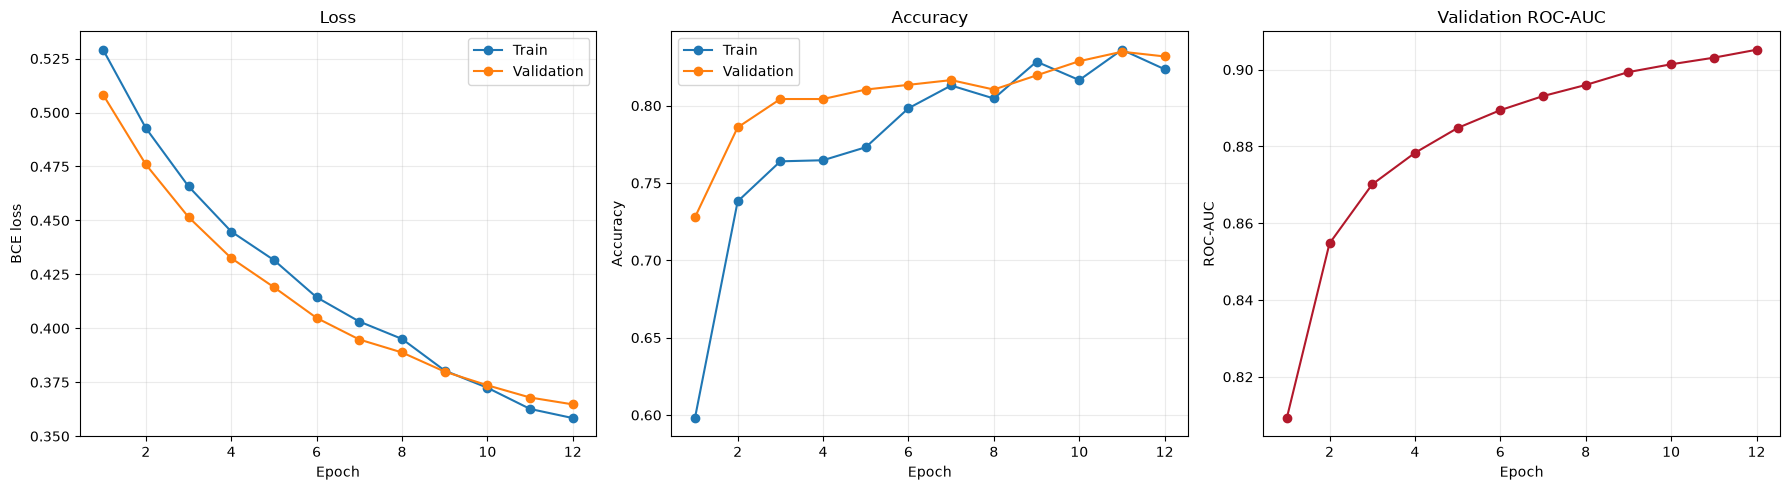

Training curves saved: C:\Users\vibhu\OneDrive\图片\文档\AMD-Digital-Twin\results\plots\baseline_training_curves.png


In [8]:
if not history.empty:
    figure, axes = plt.subplots(1, 3, figsize=(18, 5))
    axes[0].plot(history["epoch"], history["train_loss"], marker="o", label="Train")
    axes[0].plot(history["epoch"], history["validation_loss"], marker="o", label="Validation")
    axes[0].set_title("Loss")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("BCE loss")
    axes[0].legend()
    axes[0].grid(alpha=0.25)
    axes[1].plot(history["epoch"], history["train_accuracy"], marker="o", label="Train")
    axes[1].plot(history["epoch"], history["validation_accuracy"], marker="o", label="Validation")
    axes[1].set_title("Accuracy")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("Accuracy")
    axes[1].legend()
    axes[1].grid(alpha=0.25)
    axes[2].plot(history["epoch"], history["roc_auc"], marker="o", color="#b2182b")
    axes[2].set_title("Validation ROC-AUC")
    axes[2].set_xlabel("Epoch")
    axes[2].set_ylabel("ROC-AUC")
    axes[2].grid(alpha=0.25)
    figure.tight_layout()
    figure.savefig(PLOTS_ROOT / "baseline_training_curves.png", dpi=180, bbox_inches="tight")
    plt.show()
    print(f"Training curves saved: {PLOTS_ROOT / 'baseline_training_curves.png'}")
else:
    print("No curves generated because training history is empty.")

## 10. Baseline training summary

Test evaluation is intentionally omitted.

In [9]:
if history.empty:
    print("Training did not produce a summary.")
else:
    best_row = history.loc[history["roc_auc"].fillna(-np.inf).idxmax()]
    print("CONTROLLED BASELINE TRAINING SUMMARY")
    print("-" * 42)
    print(f"Best epoch: {int(best_row['epoch'])}")
    print(f"Best validation loss: {best_row['validation_loss']:.6f}")
    print(f"Best validation accuracy: {best_row['validation_accuracy']:.6f}")
    print(f"Best validation F1-score: {best_row['f1_score']:.6f}")
    print(f"Best validation ROC-AUC: {best_row['roc_auc']:.6f}")
    print(f"Saved model checkpoint: {CHECKPOINT_PATH}")
    print("Test evaluation: not performed")

CONTROLLED BASELINE TRAINING SUMMARY
------------------------------------------
Best epoch: 12
Best validation loss: 0.364735
Best validation accuracy: 0.831804
Best validation F1-score: 0.860759
Best validation ROC-AUC: 0.905193
Saved model checkpoint: C:\Users\vibhu\OneDrive\图片\文档\AMD-Digital-Twin\models\baseline_efficientnetb0_best.pth
Test evaluation: not performed
